# Residual Plot
- residuals are used to evaluate regression problems
- x-axis - predicted values
- y-axis - residuals
- ideal: random scatter
- curved/u-shaped - nonlinearity
- funnel - heteroscedasticity
- clustered points and outliers

Training: 10661 rows | 70 unique players
Validation: 2169 rows | 15 unique players
Testing: 2170 rows | 15 unique players


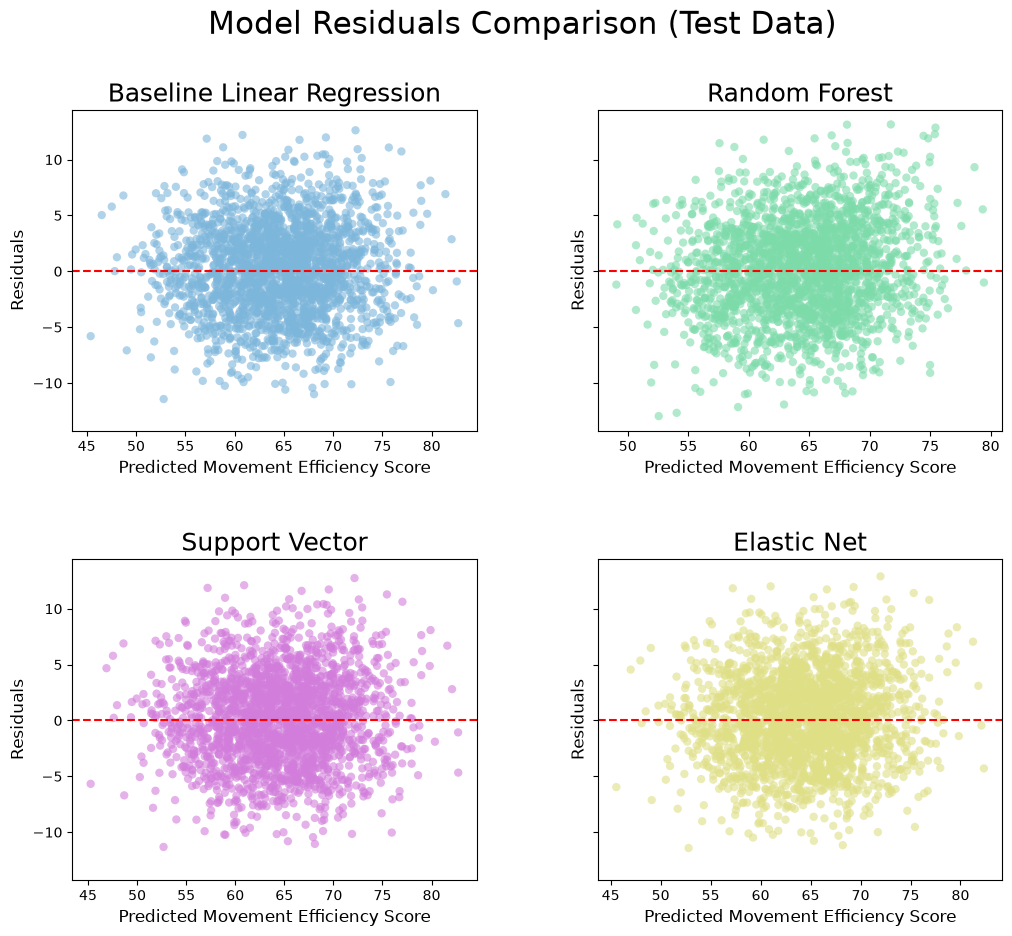

In [21]:
import joblib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
#need to access the testing fold so import from the data_splitter Python script to load and split the data
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..'))) #used to move to the parent folder
from src.data_splitter import load_data, split

#load dataset and variables
df, X, y = load_data()

#split data by groups
X_train, X_val, X_test, y_train, y_val, y_test = split(df, X, y)

#load the models using joblib
models = {
    'Baseline Linear Regression': joblib.load('baseline.joblib'),
    'Random Forest': joblib.load('random_forest.joblib'),
    'Support Vector': joblib.load('support_vector.joblib'),
    'Elastic Net': joblib.load('elastic_net.joblib')
}

#generate predictions for validation and test sets
predictions = {}
for name, model in models.items():
    predictions[name] = {
        'val': model.predict(X_val),
        'test': model.predict(X_test)
    }

#showing 2 plots next to each other at a time
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=True, gridspec_kw={'hspace': 0.4, 'wspace': 0.3})
ax1, ax2, ax3, ax4 = axes.flatten()

colors = {
    'Baseline Linear Regression': '#7db6db', 
    'Random Forest': '#7ddbaa', 
    'Support Vector': '#d27ddb', 
    'Elastic Net': '#dfdf86'
}

plot_configs = [
    (ax1, 'Baseline Linear Regression', 'Baseline Linear Regression'),
    (ax2, 'Random Forest', 'Random Forest'),
    (ax3, 'Support Vector', 'Support Vector'),
    (ax4, 'Elastic Net', 'Elastic Net')
]

for ax, title, name in plot_configs:
    y_pred = predictions[name]["test"]
    residuals = y_test - y_pred
    
    ax.set_title(title, fontsize=18)
    ax.scatter(y_pred, residuals, alpha=0.6, c=colors[name], edgecolors='none')
    ax.axhline(y=0, color='r', linestyle='--')
    ax.set_xlabel('Predicted Movement Efficiency Score', fontsize=12)
    ax.set_ylabel('Residuals', fontsize=12)

plt.suptitle('Model Residuals Comparison (Test Data)', fontsize=22)
plt.savefig('../reports/model_residuals_grid.png', dpi=300, bbox_inches='tight')
plt.show()

# Residual Analysis
- independence - may be violated since players are repeated and the errors may not be independent
## Baseline - Linear Regression
- linearity - centered evenly around y=0 line
- heteroscedasticity (constant variance) - no cone/funnel shape
- few outliers but won't dramatically affect model
- most tightly clustered points of the graphs
## Random Forest
- biased toward the upper right - slight cone shape, so likely that variance is not constant
- most outliers of all models
## Support Vector 
- plot looks basically identical with linear regression plot and elastic net plot
## Elastic Net
- plot looks basically identical with linear regression plot and support vector plot

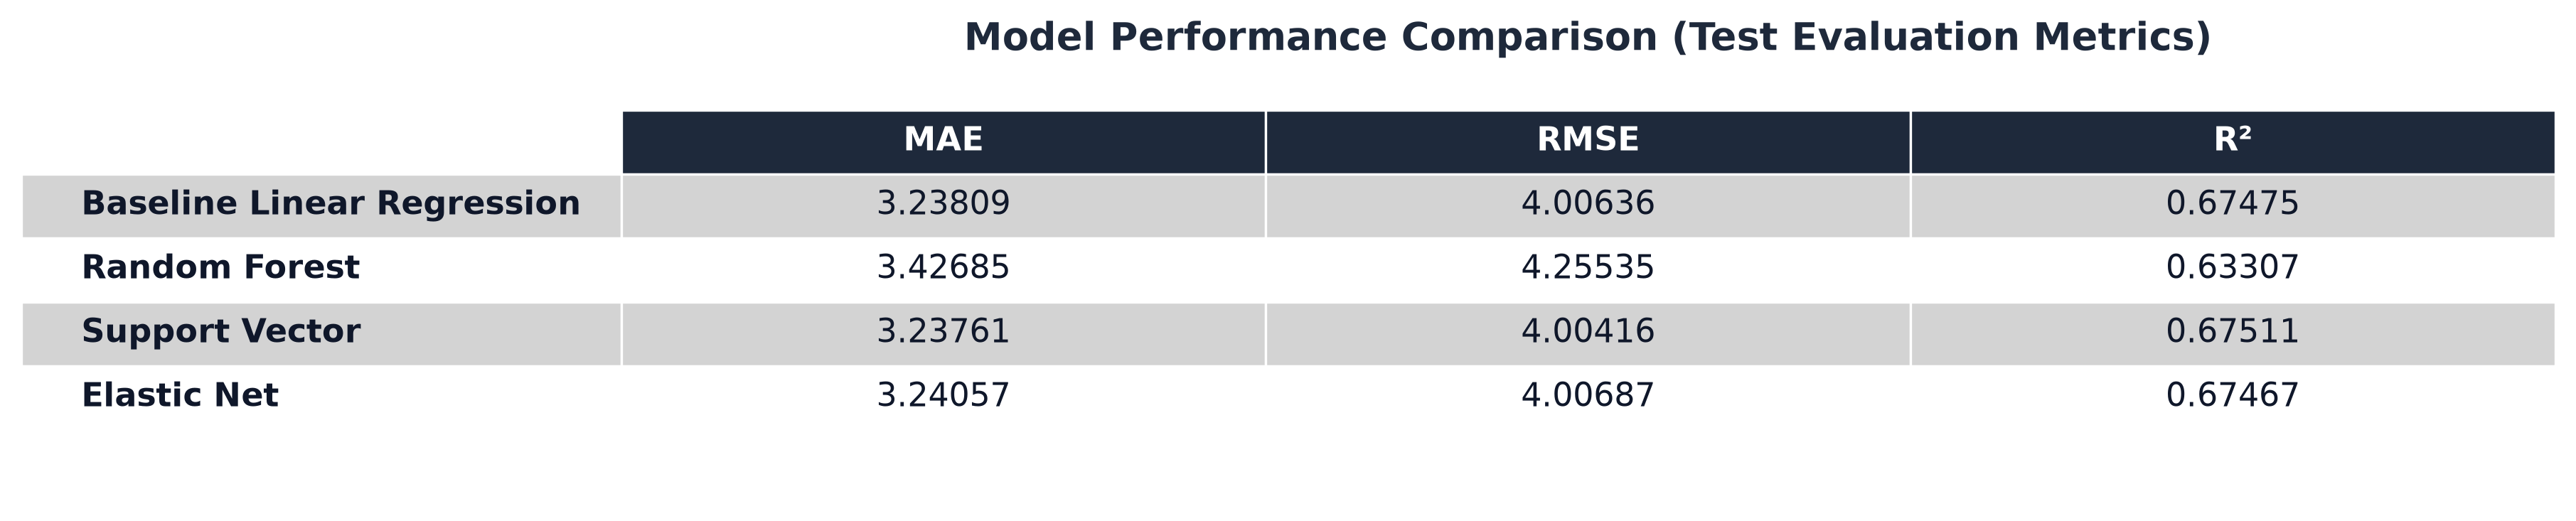

In [22]:
#comparison chart for the models
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

#evaluation metrics
metrics = []
for name, preds in predictions.items():
    #validation metrics
    metrics.append({
        'Model': name, 'Split': 'Validation',
        'MAE': mean_absolute_error(y_val, preds['val']),
        'RMSE': root_mean_squared_error(y_val, preds['val']),
        'R²': r2_score(y_val, preds['val'])
    })
    #test metrics
    metrics.append({
        'Model': name, 'Split': 'Test',
        'MAE': mean_absolute_error(y_test, preds['test']),
        'RMSE': root_mean_squared_error(y_test, preds['test']),
        'R²': r2_score(y_test, preds['test'])
    })

metrics_df = pd.DataFrame(metrics)

#only test evaluation metrics in separate table
test_df = metrics_df[metrics_df["Split"] == "Test"].drop(columns=["Split"]).set_index("Model")

fig, ax = plt.subplots(figsize=(9, 2.8), dpi=300)
ax.axis('off')
ax.axis('tight')

ax.text(0.5, 1.0, 'Model Performance Comparison (Test Evaluation Metrics)', fontsize=13, fontweight='bold', color='#1e293b', ha='center', va='center', transform=ax.transAxes)

#create table
df_to_plot = test_df.round(5)
table = ax.table(
    cellText=df_to_plot.values,
    colLabels=df_to_plot.columns,
    rowLabels=df_to_plot.index,
    loc='center',
    cellLoc='center'
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.3, 1.8) 

#styling loop
for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#ffffff')
    cell.set_linewidth(0.8)
    
    if row == 0:
        cell.set_facecolor('#1e293b')
        cell.set_text_props(weight='bold', color='white')
    elif col == -1:
        cell.set_text_props(weight='bold', color='#0f172a', ha='left')
        cell.set_facecolor('#D3D3D3' if row % 2 == 1 else '#ffffff')
    else:
        cell.set_facecolor('#D3D3D3' if row % 2 == 1 else '#ffffff')
        cell.set_text_props(color='#0f172a')

plt.savefig('../reports/model_comparison_table.png', dpi=300, bbox_inches='tight')
plt.show()

# Error Analysis from Test Set
- Support Vector performs slightly better than Linear Regression but the improvement is visible in the 3rd decimal place so not much better
- Elastic Net does slightly worse than Support Vector but not significant since in 3rd decimal place
    - does worse than linear regression in MAE and RMSE (3rd decimal place), does better in R² (4th decimal place) so not significant
- Random Forest performs substantially worse than the other 2 models in all evaluation metrics
- since linear regression and support vector with linear kernal did basically the same, the data likely has a linear relationship
- random forest is likely doing worse because the data has a linear relationship

# Conclusion
## Best Model
- best model based on evaluation metrics is technically Support Vector but the increase in performance is basically non-negligible because it's visible at the 3rd decimal point
      - explains why Linear Regression's and Support Vector's residual plots look identical
- Elastic Net also has basically the same evaluation metrics which explains the similarity in Linear Regression's residual plot (and Support Vector's)
- worst model: random forest, likely due to a non-linear relationship in the data
## Limitations
- samples may be dependent because players are repeated multiple times
- using 23 input features, so some could be noise that is distracting the model
- model may be experiencing multicollinearity because some input features are likely related (ex: elbow_angular_acceleration_deg_s2 and wrist_angular_acceleration_deg_s2)
## Next Steps
- determine which input variables are noise and can be removed
- test other linear models and try to do significantly better than the baseline linear regression

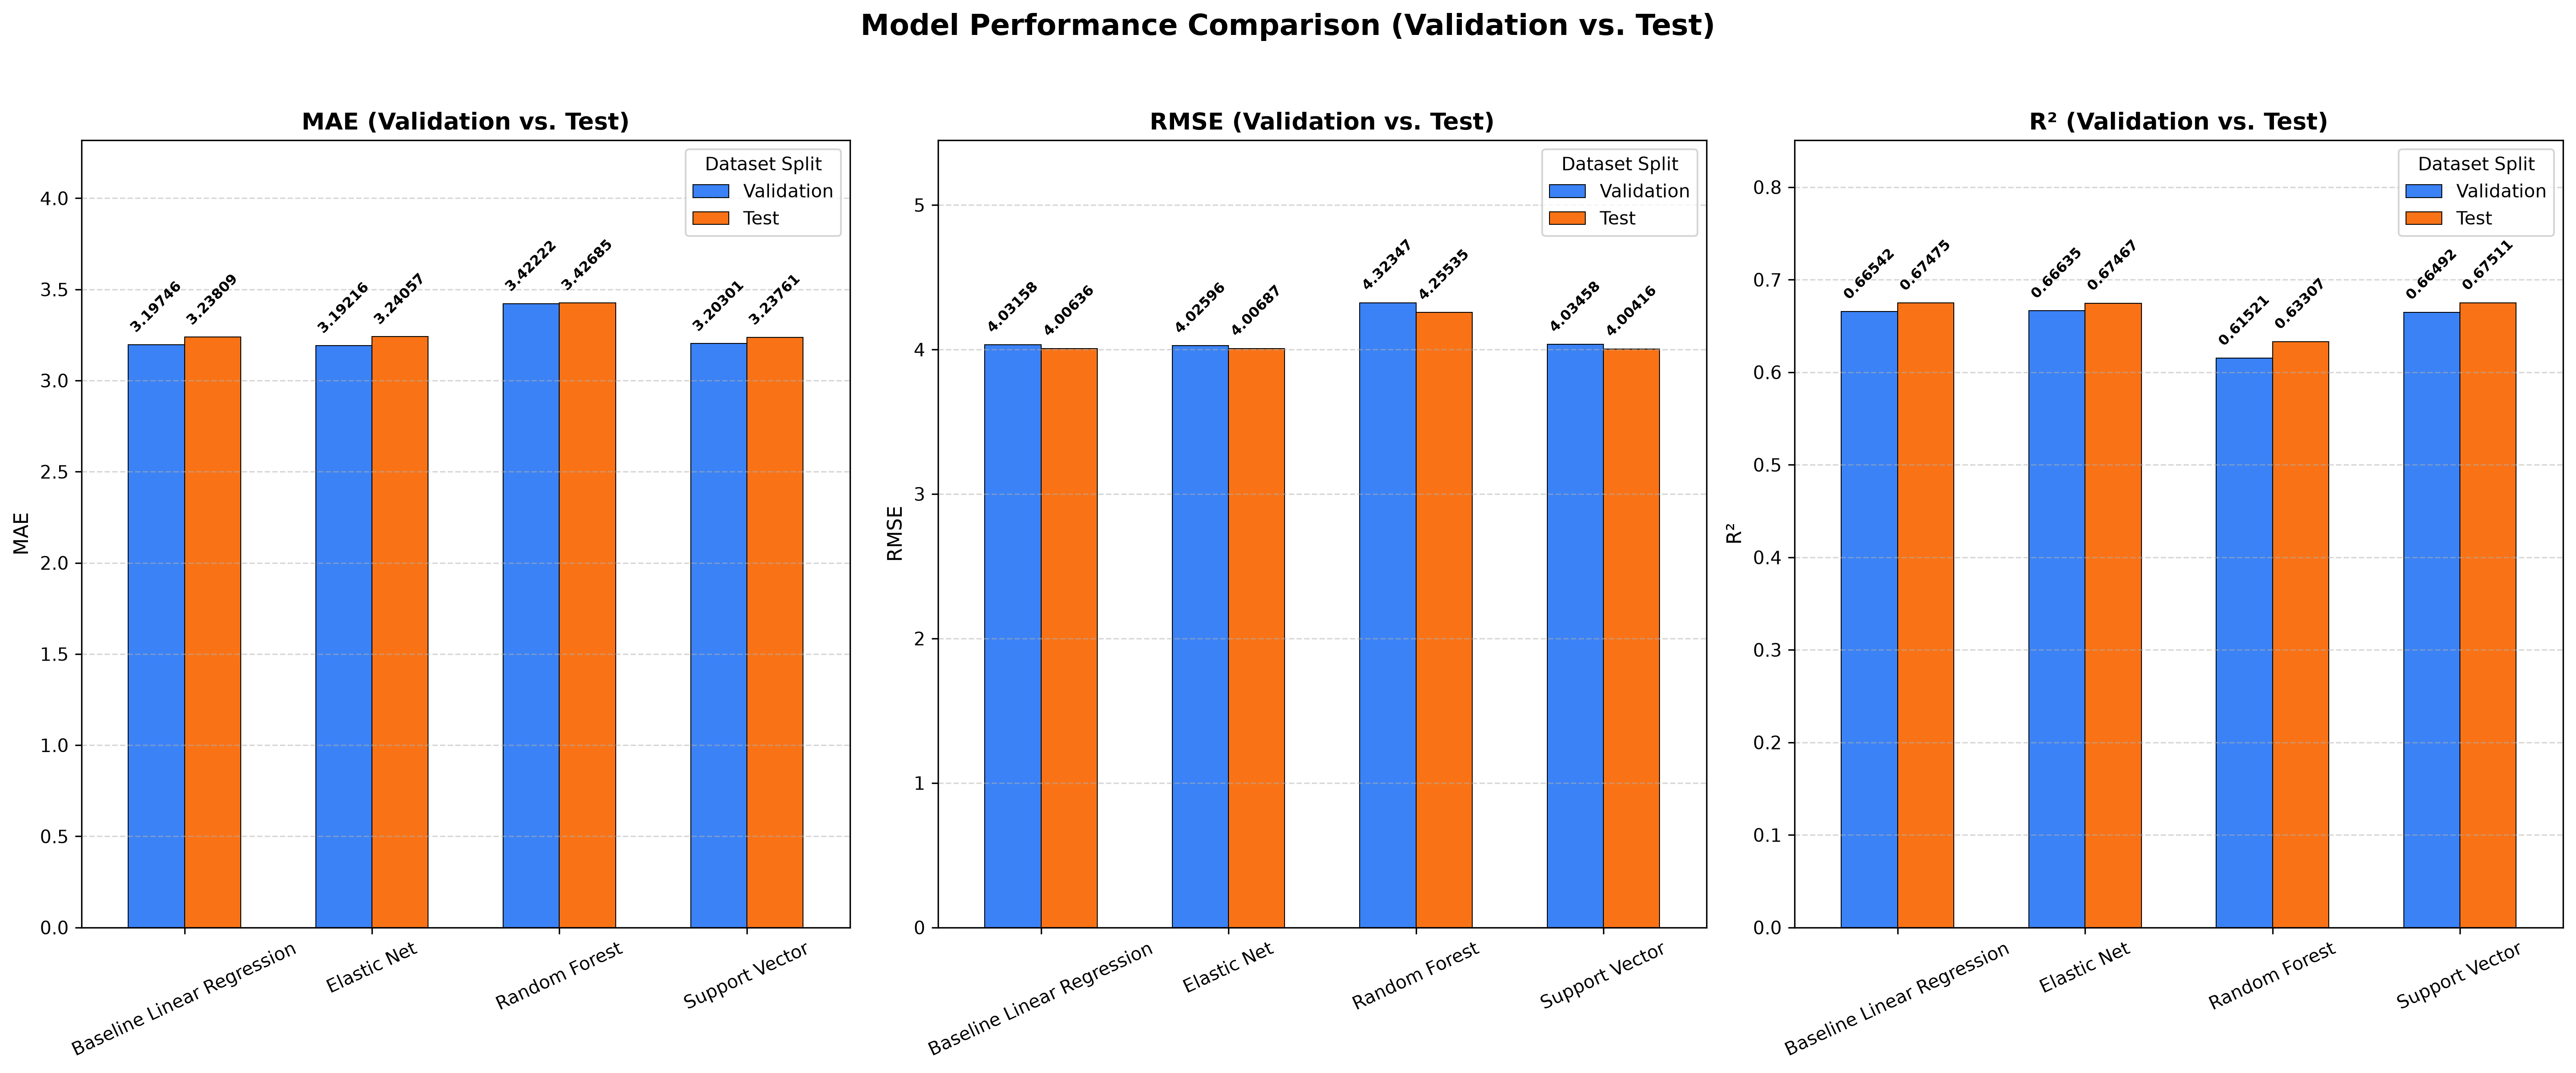

In [23]:
#adding validation to the analysis to observe how models are doing across sets and how seeing unseen data affects the predictions
metrics_df = metrics_df.round(5)

fig, axes = plt.subplots(1, 3, figsize=(20, 8), dpi=300)
metrics_to_plot = ["MAE", "RMSE", "R²"]
split_colors = {'Validation': '#3b82f6',
                'Test': '#f97316'
               }

for i, metric in enumerate(metrics_to_plot):
    ax = axes[i]
    #pivot data so models are rows and splits are columns
    pivot_df = metrics_df.pivot(index='Model', columns='Split', values=metric)
    pivot_df = pivot_df[['Validation', 'Test']]

    pivot_df.plot(
        kind='bar', 
        ax=ax, 
        color=[split_colors['Validation'], split_colors['Test']], 
        width=0.6,
        edgecolor='black',
        linewidth=0.5
    )
    #number labels on top of each bar
    for container in ax.containers:
        ax.bar_label(
            container, 
            fmt='%.5f',
            padding=5,
            rotation=45,
            fontsize=8, 
            fontweight='bold'
    )
        
    ax.set_title(f'{metric} (Validation vs. Test)', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(metric, fontsize=11)
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(title='Dataset Split', frameon=True)

    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.2)

plt.suptitle('Model Performance Comparison (Validation vs. Test)', fontsize=16, fontweight='bold', y=1.03)
plt.tight_layout()
plt.savefig('../reports/val_vs_test_bar_chart.png', dpi=300, bbox_inches='tight')
plt.show()   

# Conclusions from comparing test vs validation performance
## Validation observations
- Elastic Net is able to do slightly better than baseline Linear Regression for every metric
- Support Vector does about the same as Linear Regression (with Linear Regression doing slightly better)
- Random Forest does substantially worse

## Test observations
- all models do worse for MAE
  - Elastic Net no longer does better than Linear Regression, performing slightly worse than Linear Regression and Support Vector
  - MAE for Random Forest is almost the same (changes in 3rd decimal point) while degrade is much more obvious in the other models
- all models do better for RMSE
  - while Linear Regression and Elastic Net do basically the same, Support Vector does slightly better
  - Random Forest has the most substantial improvement from validation to test set
- R² increases for all models so better able to explain variability in data
  - Linear Regression and Elastic Net are basically the same
  - Support Vector slightly higer, performs best
  - Random Forest much lower

## Other conclusions
- Linear Regression, Support Vector, Elastic Net do very similar, suggests the data is robust and linear
- Random Forest shows the greatest improvement from validation to test
- models aren't overfitting because no significant drop in performance
- cannot truly determine a best model on performance alone between Linear Regression, Support Vector, Elastic Net

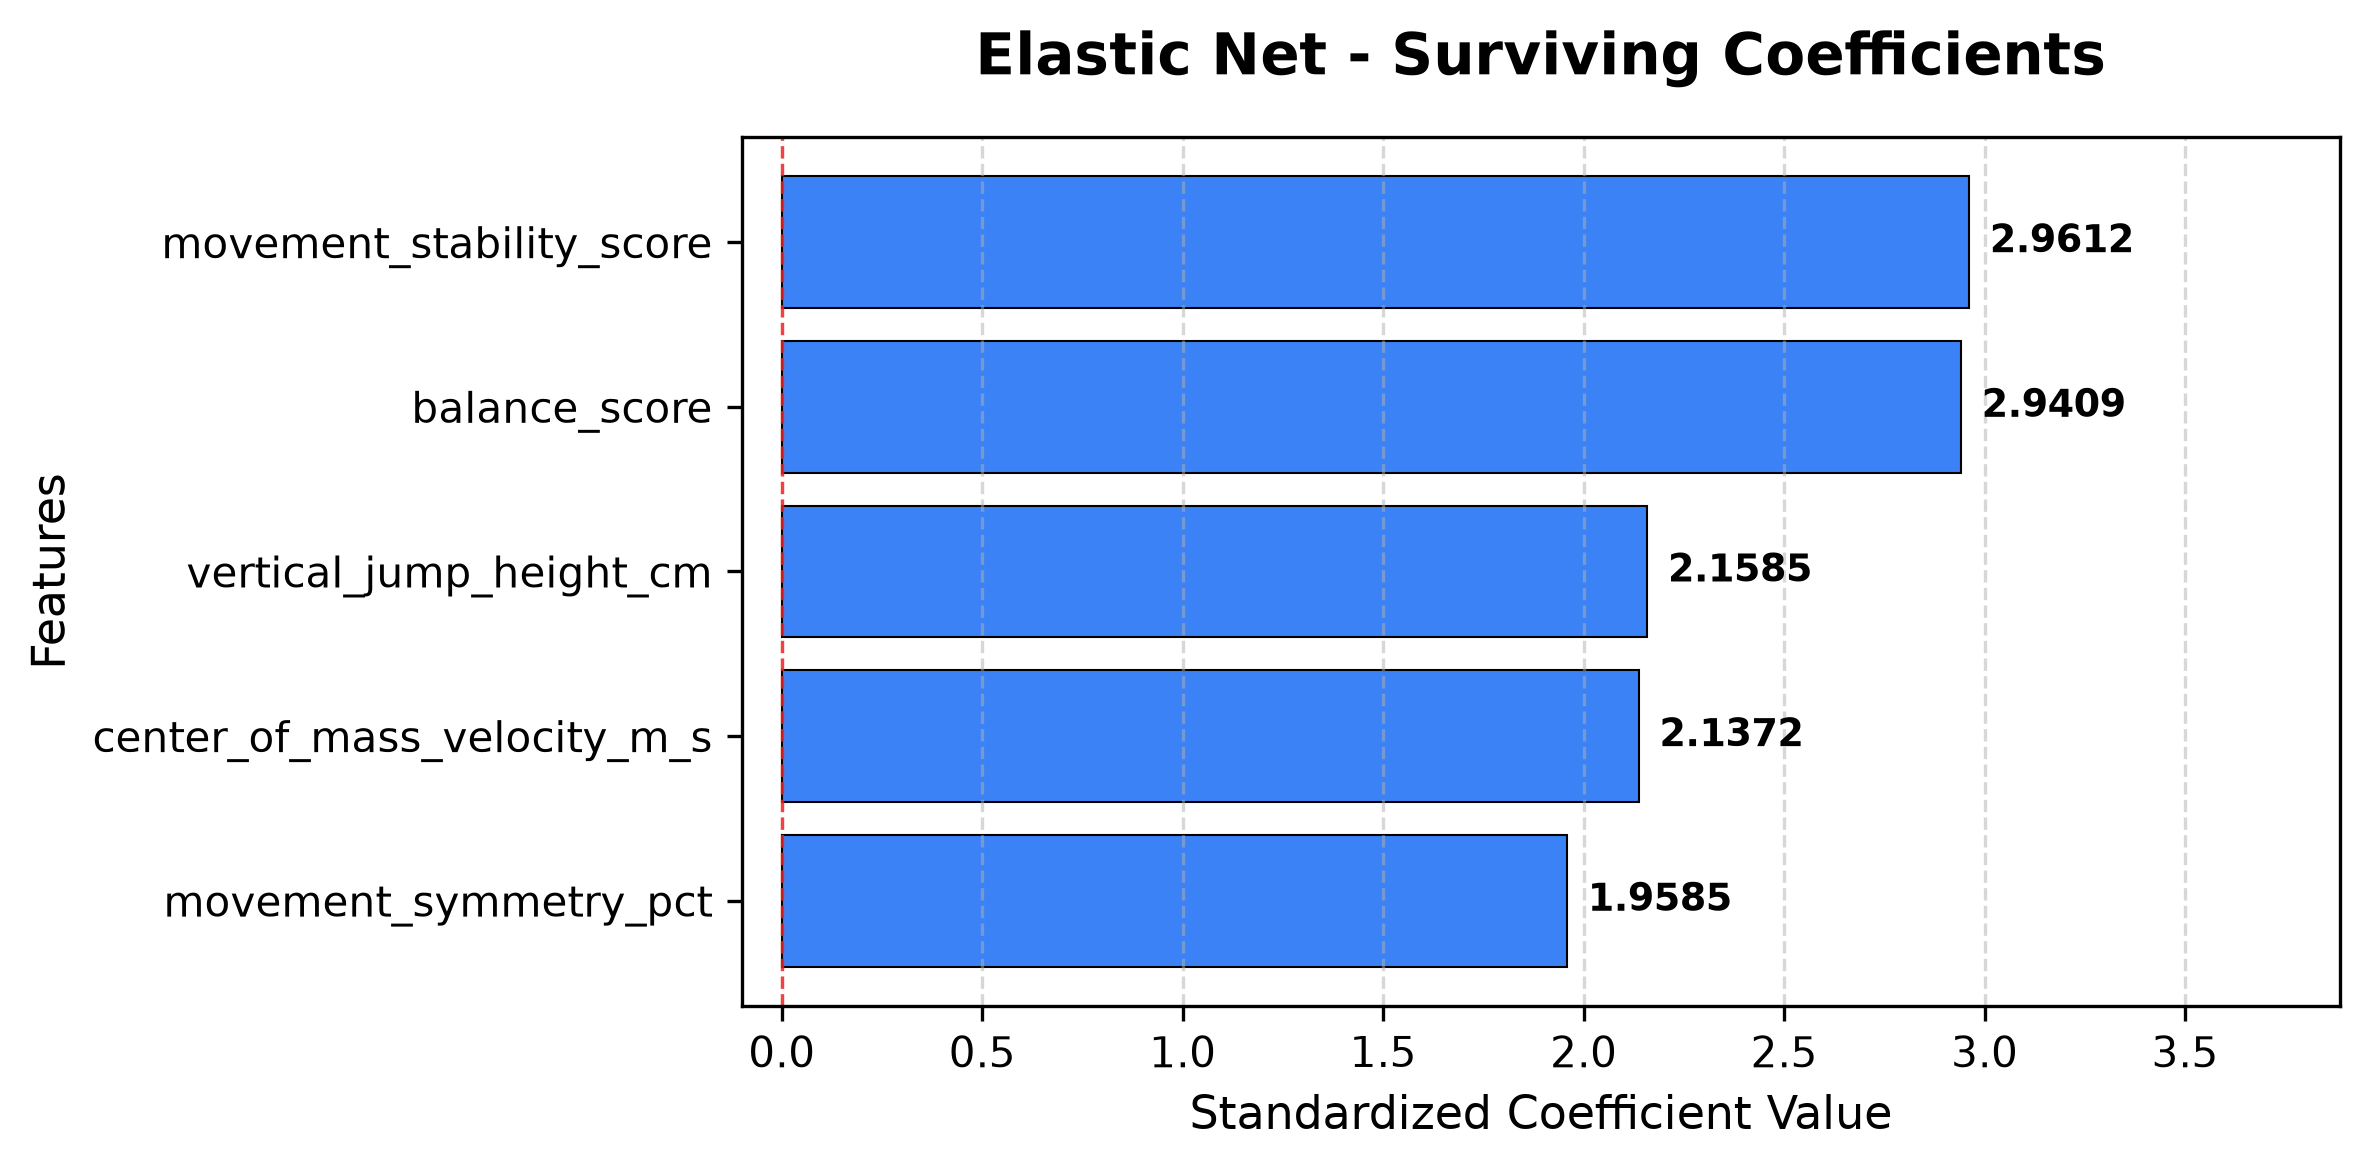

In [31]:
#chart showing which features were selected in elastic net and the value of each coefficient (can see strength)
feature_names = X.columns.tolist()
en = models['Elastic Net']
coefficients = en.named_steps['regressor'].coef_

#extract features from pipeline to account for one-hot encoding
try:
    feature_names = en.named_steps['preprocessor'].get_feature_names_out()
except (AttributeError, KeyError):
    try:
        feature_names = en.named_steps['encoder'].get_feature_names_out(X.columns)
    except Exception:
        if len(X.columns) == len(coefficients):
            feature_names = X.columns.tolist()
        else:
            feature_names = [f"Feature {i}" for i in range(len(coefficients))]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

#keep only names
coef_df['Feature'] = coef_df['Feature'].str.replace("num__", "", regex=False)

#only want kept coefficients
kept = coef_df[coef_df['Coefficient'] != 0].copy()
#sort by most impact
kept['Abs_Coef'] = kept['Coefficient'].abs()
kept = kept.sort_values(by='Abs_Coef', ascending=True)

fig, ax = plt.subplots(figsize=(8, max(4, len(kept) * 0.4)), dpi=300)

bars = ax.barh(
    kept['Feature'], 
    kept['Coefficient'], 
    color='#3b82f6', 
    edgecolor='black', 
    linewidth=0.5
)

ax.bar_label(
    bars, 
    fmt='%.4f', 
    padding=5, 
    fontsize=9, 
    fontweight='bold'
)

ax.set_title('Elastic Net - Surviving Coefficients', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Standardized Coefficient Value', fontsize=11)
ax.set_ylabel('Features', fontsize=11)
ax.axvline(x=0, color='r', linestyle='--', linewidth=0.8, alpha=0.7)
ax.grid(axis='x', linestyle='--', alpha=0.5)

xmin, xmax = ax.get_xlim()
ax.set_xlim(xmin * 1.2 if xmin < 0 else -0.1, xmax * 1.25)

plt.tight_layout()
plt.savefig('../reports/elastic_net_coefficients.png', dpi=300, bbox_inches='tight')
plt.show()

# Observations about Elastic Net kept features
- 23 input variables shrunk to 5 through Lasso Regularization
- movement_stability_score and balance_score almost equal and both have largest impact
- vertical_jump_height_cm and center_of_mass_velocity_m_s - almost equal, 2nd most impact
- all values are positive so when any of these increase, the movement_efficiency_score automatically increases
- rest of the variables have been set to equal 0 (Lasso Regularization)